# Two-leg reconciliation, capital and turnover
Frozen study eed008040d6c6d18. Post-study evidence review, hypothetical fills.


In [1]:
from pathlib import Path
import os,sys,html
root=Path.cwd()
if not (root/'carry').exists():root=root.parent
os.chdir(root)
sys.path.insert(0,str(root))
def show_svg(svg):
    if '_emit_data' in globals():_emit_data({'image/svg+xml':svg})
    else:
        from IPython.display import display,SVG
        display(SVG(svg))
def show_table(headers,rows):
    markup='<table><thead><tr>'+''.join('<th>'+html.escape(str(v))+'</th>' for v in headers)+'</tr></thead><tbody>'+''.join('<tr>'+''.join('<td>'+html.escape(str(v))+'</td>' for v in row)+'</tr>' for row in rows)+'</tbody></table>'
    if '_emit_data' in globals():_emit_data({'text/html':markup})
    else:
        from IPython.display import display,HTML
        display(HTML(markup))


## Question
Does apparent funding income survive both legs, separate collateral, commissions and switching? Historical metrics come from the frozen study. An independent deterministic case below exercises the actual engine. Each historical asset/policy/partition uses its own 100,000 USDT sleeve.

In [2]:
import csv,json,math,statistics
from pathlib import Path
from carry.figures import lines,bars
from carry.engine import Config,replay,stress_case
from carry.run import sample,forecast_comparison,summarize,golden_case

def read_csv(name):
    with Path(name).open() as f:return list(csv.DictReader(f))


In [3]:
rows=sample('BTCUSDT')[:12]
ledger,fills=replay(rows,Config(),'continuous')
show_table(['UTC','Spot units','Perp units','Funding cash','Equity','Bridge residual'],[[r['timestamp'],round(r['spot_qty'],4),round(r['perp_qty'],4),round(r['funding_cash'],4),round(r['equity'],4),round(r['reconciliation_error'],9)] for r in ledger[:5]])
assert ledger[1]['funding_cash']==0
assert max(abs(r['reconciliation_error']) for r in ledger)<1e-6

UTC,Spot units,Perp units,Funding cash,Equity,Bridge residual
2025-01-01T00:00:00Z,0.0,0.0,-0.0,100000.0,0.0
2025-01-01T08:00:00Z,0.9156,-0.9156,-0.0,99891.1885,-0.0
2025-01-01T16:00:00Z,0.9156,-0.9156,6.6364,99895.1727,-0.0
2025-01-02T00:00:00Z,0.9156,-0.9156,7.4024,99888.1292,0.0
2025-01-02T08:00:00Z,0.9156,-0.9156,8.006,99883.445,-0.0


## Accounting bridge
Equity is spot cash + spot market value + perp collateral + unrealized perp P&L. Net P&L is both leg P&Ls + funding - commissions - financing. Slippage is embedded once in leg P&L. A collateral transfer is not profit. The capital denominator includes idle collateral and cash.

In [4]:
summary=read_csv('artifacts/market/summary.csv')
hold=[r for r in summary if r['partition']=='holdout' and r['policy'] in ('spot','continuous','threshold')]
show_table(['Asset','Policy','Spot P&L','Perp P&L','Funding','Fees','Net P&L'],[[r['symbol'],r['policy'],*[round(float(r[k]),2) for k in ('spot_pnl','perp_pnl','funding','fees','net_pnl')]] for r in hold])
for r in summary:
    bridge=sum(float(r[k]) for k in ('spot_pnl','perp_pnl','funding'))-float(r['fees'])
    assert abs(bridge-float(r['net_pnl']))<1e-6

Asset,Policy,Spot P&L,Perp P&L,Funding,Fees,Net P&L
BTCUSDT,spot,-12833.51,0.0,0.0,97.6,-12931.12
BTCUSDT,continuous,-12833.51,12788.1,566.06,146.38,374.27
BTCUSDT,threshold,-3580.36,1763.35,409.59,6729.98,-8137.4
ETHUSDT,spot,-15410.34,0.0,0.0,94.62,-15504.96
ETHUSDT,continuous,-15410.34,15367.72,495.99,141.91,311.46
ETHUSDT,threshold,-7475.77,4666.6,309.68,7752.96,-10252.43


In [5]:
turnover=read_csv('artifacts/review/turnover.csv')
selected=[r for r in turnover if r['partition']=='holdout' and r['policy'] in ('continuous','threshold','forecast_rolling_mean')]
show_table(['Asset','Policy','Fill count','Two-leg turnover / capital','Funding','Fees'],[[r['symbol'],r['policy'],r['fills'],round(float(r['turnover_over_capital']),2),round(float(r['funding']),2),round(float(r['fees']),2)] for r in selected])

Asset,Policy,Fill count,Two-leg turnover / capital,Funding,Fees
BTCUSDT,continuous,4,1.95,566.06,146.38
BTCUSDT,threshold,164,89.76,409.59,6729.98
BTCUSDT,forecast_rolling_mean,32,17.25,394.02,1291.32
ETHUSDT,continuous,4,1.89,495.99,141.91
ETHUSDT,threshold,192,103.83,309.68,7752.96
ETHUSDT,forecast_rolling_mean,49,24.48,195.99,1798.96


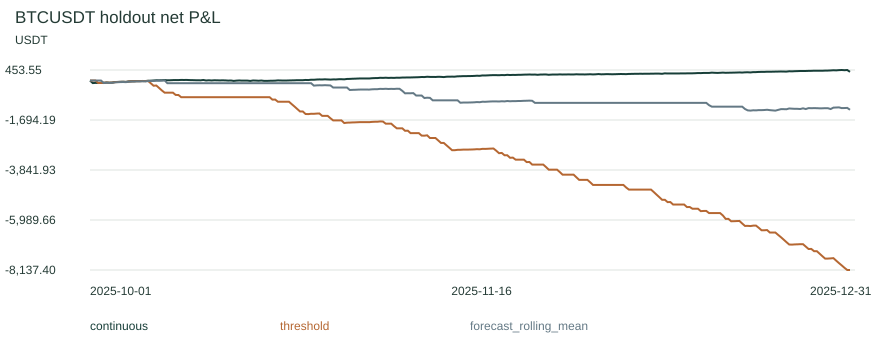

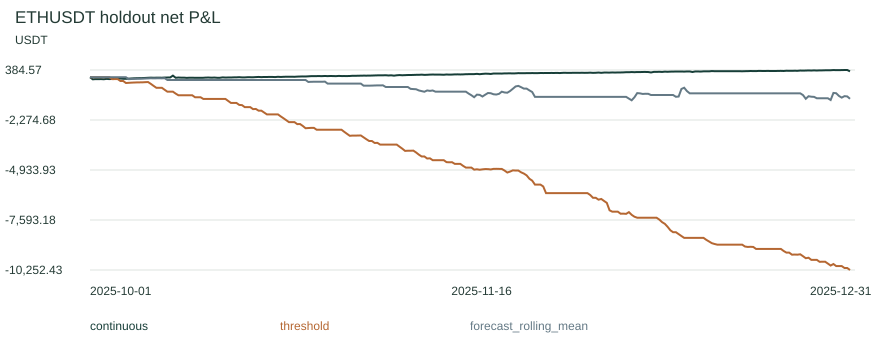

In [6]:
curves=read_csv('artifacts/review/curves.csv')
for symbol in ('BTCUSDT','ETHUSDT'):
    group={policy:[r for r in curves if r['symbol']==symbol and r['partition']=='holdout' and r['policy']==policy] for policy in ('continuous','threshold','forecast_rolling_mean')}
    show_svg(lines(symbol+' holdout net P&L',[r['timestamp'][:10] for r in group['continuous']],{k:[float(r['net_pnl']) for r in v] for k,v in group.items()}))

## Decision
The naive threshold earns funding but spends more on switching. A smoother rule reduces turnover; this should not be confused with a proven forecasting edge. Continuous carry has different operational and collateral exposure, so policy selection cannot use net P&L alone. Full close-out costs are included at every partition end.

## Conclusion and artifacts
The engine reconciles the sampled ledger, and the trading-cost mechanism explains the negative threshold result. Sources: frozen `summary.csv`, `trades.csv` (private), and derived public `turnover.csv` / `curves.csv`. Workbook Review traces all 36 historical sleeves; Scenario computes independent economics. No new strategy was fitted in this notebook.